<a href="https://colab.research.google.com/github/fifanuurunhalizah09/PCVK_Ganjil2026/blob/main/week09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

# 1.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2.

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 3.

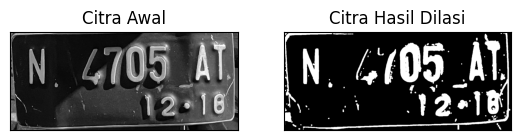

In [5]:
#Dilasi tanpa library
def dilasi_citra(F, w):
    #size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = int((w - 1) / 2)

    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# === TAMBAHAN: cek dulu file-nya ada atau tidak ===
path = '/content/drive/MyDrive/PCVK 2026/plat nomer.jpg'
import os
if not os.path.exists(path):
    print("File tidak ada di path:", path)
    print("Isi folder:")
    try:
        print(os.listdir('/content/drive/MyDrive/PCVK 2026/'))
    except:
        print(os.listdir('/content/drive/MyDrive/'))
    raise SystemExit("Perbaiki path dulu!")

img_d = cv2.imread(path, 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# 4.

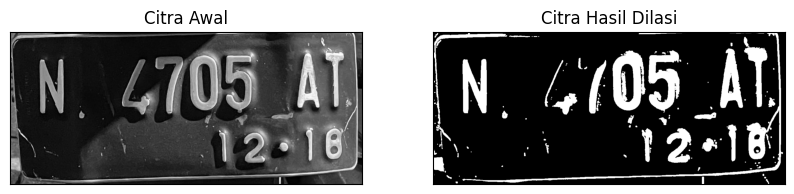

In [7]:
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi, cmap='gray'), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

# 5.

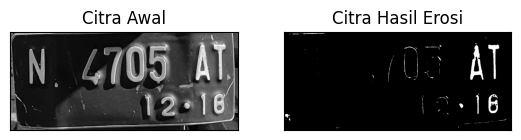

In [8]:
#Erosi Tanpa Library
def erosi_citra(F, k):
    m, n = F.shape

    #Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = int((k - 1) / 2)

    imgE = np.zeros((m, n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

# 6.

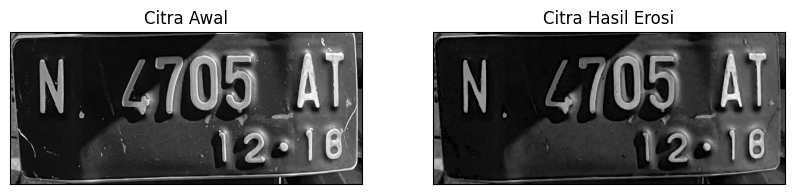

In [9]:
#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion, cmap='gray'), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

# 7.

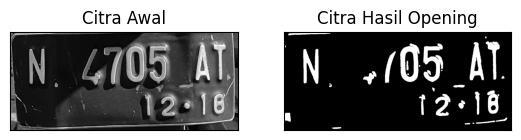

In [10]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret_o, thresh_o = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7
# Opening = Erosi dulu, baru Dilasi
imgO = dilasi_citra(erosi_citra(thresh_o, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

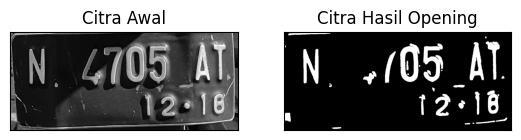

In [11]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret_o, thresh_o = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7
# Opening = Erosi dulu, baru Dilasi
imgO = dilasi_citra(erosi_citra(thresh_o, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

# 8.

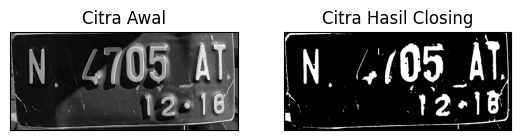

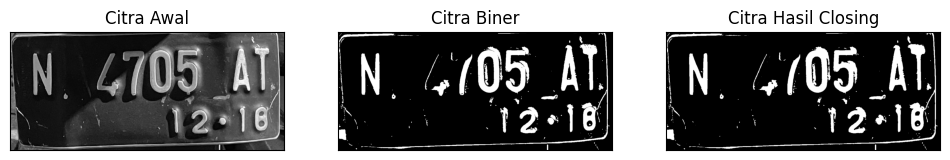

In [12]:
img_c = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret_c, thresh_c = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 7
# Closing = Dilasi dulu, baru Erosi
imgC = erosi_citra(dilasi_citra(thresh_c, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# ==========================================
# Operasi Closing Dengan Library
# ==========================================
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
class_closing = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(class_closing, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# 9.

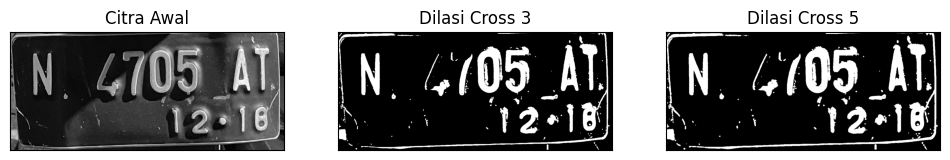

In [13]:
def dilasi_cross(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    if w == 3:
        SED = np.array([[0, 1, 0],
                        [1, 1, 1],
                        [0, 1, 0]], dtype=np.uint8)
    elif w == 5:
        SED = np.array([[0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0],
                        [1, 1, 1, 1, 1],
                        [0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0]], dtype=np.uint8)

    constant1 = int((w - 1) / 2)

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

# Cross 3x3
w = 3
imgD_3 = dilasi_cross(thresh, w)
# Cross 5x5
w = 5
imgD_5 = dilasi_cross(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_3, cmap='gray')
plt.title('Dilasi Cross 3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgD_5, cmap='gray')
plt.title('Dilasi Cross 5'), plt.xticks([]), plt.yticks([])
plt.show()

# 10.

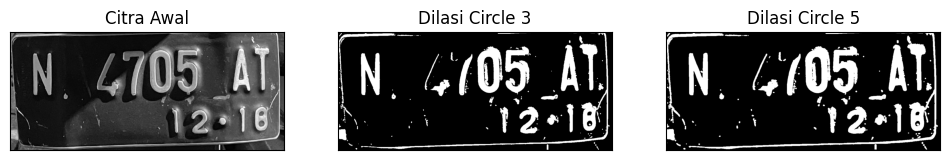

In [15]:
def dilasi_circle(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED) Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

# Circle 3x3
w = 3
imgD_c3 = dilasi_circle(thresh, w)
# Circle 5x5
w = 5
imgD_c5 = dilasi_circle(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_c3, cmap='gray')
plt.title('Dilasi Circle 3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgD_c5, cmap='gray')
plt.title('Dilasi Circle 5'), plt.xticks([]), plt.yticks([])
plt.show()

# 11.

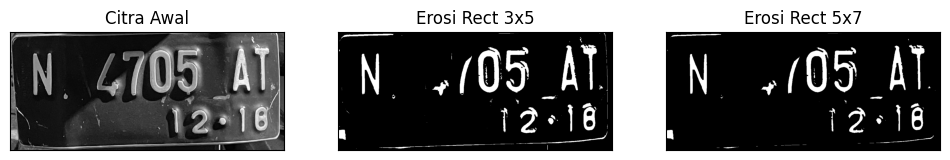

In [17]:
def erosi_rect(F, p, l):
    m, n = F.shape
    # Generate SE persegi panjang
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (l, p))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant2, m - constant2):
        for j in range(constant1, n - constant1):
            temp = F[i - constant2 : i + constant2 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# Rectangle 3x5 (p=3, l=5)
imgE_r35 = erosi_rect(thresh, 3, 5)
# Rectangle 5x7 (p=5, l=7)
imgE_r57 = erosi_rect(thresh, 5, 7)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_r35, cmap='gray')
plt.title('Erosi Rect 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgE_r57, cmap='gray')
plt.title('Erosi Rect 5x7'), plt.xticks([]), plt.yticks([])
plt.show()

# 12.

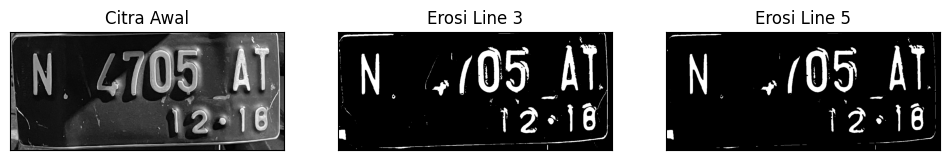

In [19]:
def erosi_line(F, k):
    m, n = F.shape
    # SE Line Vertikal
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# Line Vertikal 3
imgE_l3 = erosi_line(thresh, 3)
# Line Vertikal 5
imgE_l5 = erosi_line(thresh, 5)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_l3, cmap='gray')
plt.title('Erosi Line 3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgE_l5, cmap='gray')
plt.title('Erosi Line 5'), plt.xticks([]), plt.yticks([])
plt.show()

# 13.

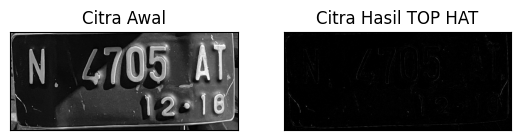

In [20]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Baca gambar (gunakan plat nomer atau gambar kucing sesuai modul)
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/plat nomer.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_gray, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

# 14.

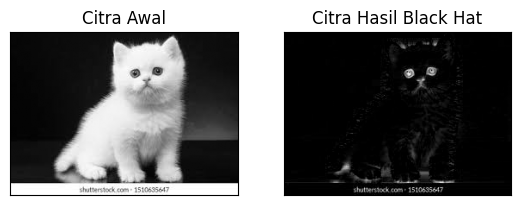

In [21]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Baca gambar
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/kitten.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Gunakan kernel sesuai modul
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_gray, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

# 15.

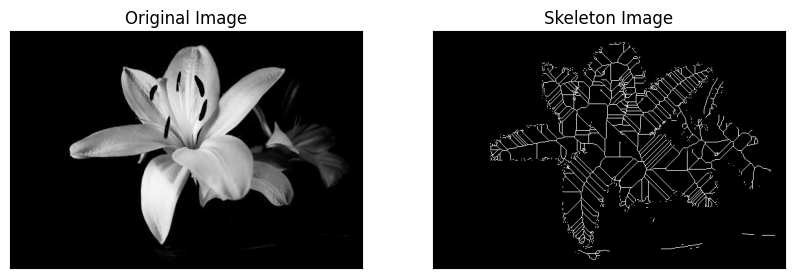

In [26]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK 2026/lily.jpg', 0)

# Thresholding
binary = img > filters.threshold_triangle(img)

# Konversi True/False jadi 1/0
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# Skeletonize
skeleton = skeletonize(binary_cp)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.show()

# 16.

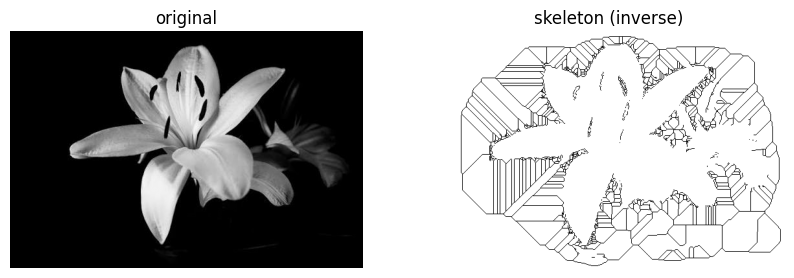

In [28]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK 2026/lily.jpg')[..., 0]

# Invers: kita mau bagian hitam jadi True
binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# Gunakan colormap terbalik: gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

# 17.

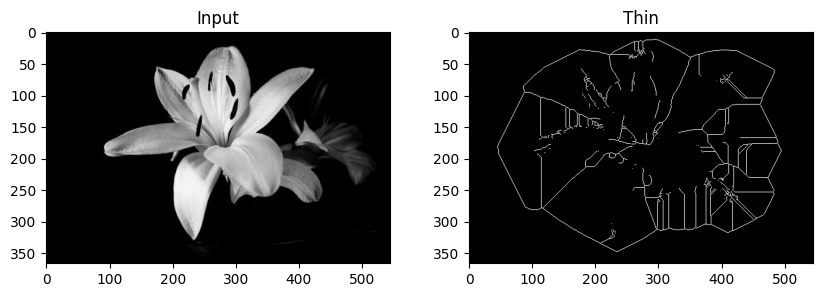

In [29]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

# Baca gambar dan konversi ke grayscale
image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK 2026/lily.jpg')))

# Thresholding
image_binary = image < 0.5

# Skeletonize dan Thin
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.show()

# TUGAS

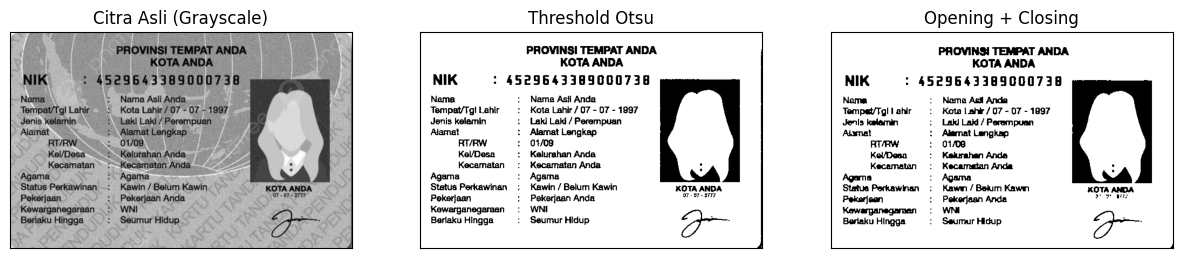

In [31]:
# 1. Baca citra KTP dan ubah ke grayscale
ktp = cv2.imread('/content/drive/MyDrive/PCVK 2026/ktp_fulani.jpg')
gray_ktp = cv2.cvtColor(ktp, cv2.COLOR_BGR2GRAY)

# 2. Thresholding (Otsu)
ret, thresh_ktp = cv2.threshold(gray_ktp, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Operasi Morfologi (Opening untuk menghilangkan noise kecil)
kernel = np.ones((2, 2), np.uint8) # sesuaikan ukuran kernel
opening_ktp = cv2.morphologyEx(thresh_ktp, cv2.MORPH_OPEN, kernel)

# 4. Operasi Closing (untuk menutup celah huruf yang terputus)
closing_ktp = cv2.morphologyEx(opening_ktp, cv2.MORPH_CLOSE, kernel)

# Tampilkan hasil
plt.figure(figsize=(15, 6))
plt.subplot(131), plt.imshow(gray_ktp, cmap='gray')
plt.title('Citra Asli (Grayscale)'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh_ktp, cmap='gray')
plt.title('Threshold Otsu'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closing_ktp, cmap='gray')
plt.title('Opening + Closing'), plt.xticks([]), plt.yticks([])
plt.show()